<a href="https://colab.research.google.com/github/sofilukash/math_modeling/blob/main/lab1/task1_lissajous_chebyshev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 1. Завдання 1
## Фігури Лісажу та поліном Чебишева

**Мета:** побудувати фігури Лісажу

$$x=\cos(\omega_1 t+\varphi_1),\qquad y=\cos(\omega_2 t+\varphi_2)$$

1-го рангу ($\omega_1/\omega_2=1$) та 2-го рангу ($\omega_1/\omega_2=2$); показати, як змінюється фігура при зміні
різниці фаз $\Delta\varphi$ і при $\omega_1/\omega_2\approx1$ ($\approx2$); побудувати графік полінома Чебишева
$T_n(x)=\cos(n\arccos x)$, $3\le n\le7$.

**Бібліотеки:** `numpy`, `matplotlib`. Малюнки зберігаються у папку `results/`.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SAVE_DIR = "results"                       # папка з малюнками для звіту
os.makedirs(SAVE_DIR, exist_ok=True)

# Різниця фаз Δφ = kπ/4, k = 0…7: підписи для графіків (LaTeX) і для таблиць (Unicode)
PHASE_LABELS = ["0", r"\pi/4", r"\pi/2", r"3\pi/4", r"\pi", r"5\pi/4", r"3\pi/2", r"7\pi/4"]
PHASE_TEXT = ["0", "π/4", "π/2", "3π/4", "π", "5π/4", "3π/2", "7π/4"]


def save(fig, name):
    """Зберегти малюнок у results/."""
    path = os.path.join(SAVE_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[збережено] {path}")


def lissajous(w1, w2, phi1, phi2, t):
    """Фігура Лісажу: x = cos(ω1·t + φ1), y = cos(ω2·t + φ2)."""
    return np.cos(w1 * t + phi1), np.cos(w2 * t + phi2)


def draw(ax, x, y, title, lw=1.6):
    """Одна фігура в квадраті [-1, 1]²; червона точка — початок кривої."""
    ax.plot(x, y, lw=lw)
    ax.plot(x[0], y[0], "o", ms=4, color="tab:red")
    ax.set_aspect("equal")
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([-1, 0, 1])
    ax.set_title(title, fontsize=10)


def sweep_figure(make_xy, title, fname):
    """Сітка 2×4: фігура при Δφ = 0, π/4, …, 7π/4; make_xy(Δφ) повертає (x, y)."""
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for k, ax in enumerate(axes.ravel()):
        x, y = make_xy(k * np.pi / 4)
        draw(ax, x, y, rf"$\Delta\varphi={PHASE_LABELS[k]}$")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(h_pad=2)
    save(fig, fname)
    plt.show()

## 1. Фігури 1-го рангу: $\omega_1/\omega_2 = 1$

Беремо $x=\cos t$, $y=\cos(t+\Delta\varphi)$ і змінюємо $\Delta\varphi$ від $0$ до $7\pi/4$ з кроком $\pi/4$.
Виключивши $t$, отримуємо $x^2+y^2-2xy\cos\Delta\varphi=\sin^2\Delta\varphi$ — **еліпс** із півосями
$a=\sqrt{1+|\cos\Delta\varphi|}$, $b=\sqrt{1-|\cos\Delta\varphi|}$; велика вісь лежить на прямій $y=x$ при
$\cos\Delta\varphi>0$ і на $y=-x$ при $\cos\Delta\varphi<0$.

[збережено] results/fig1_lissajous_rank1.png


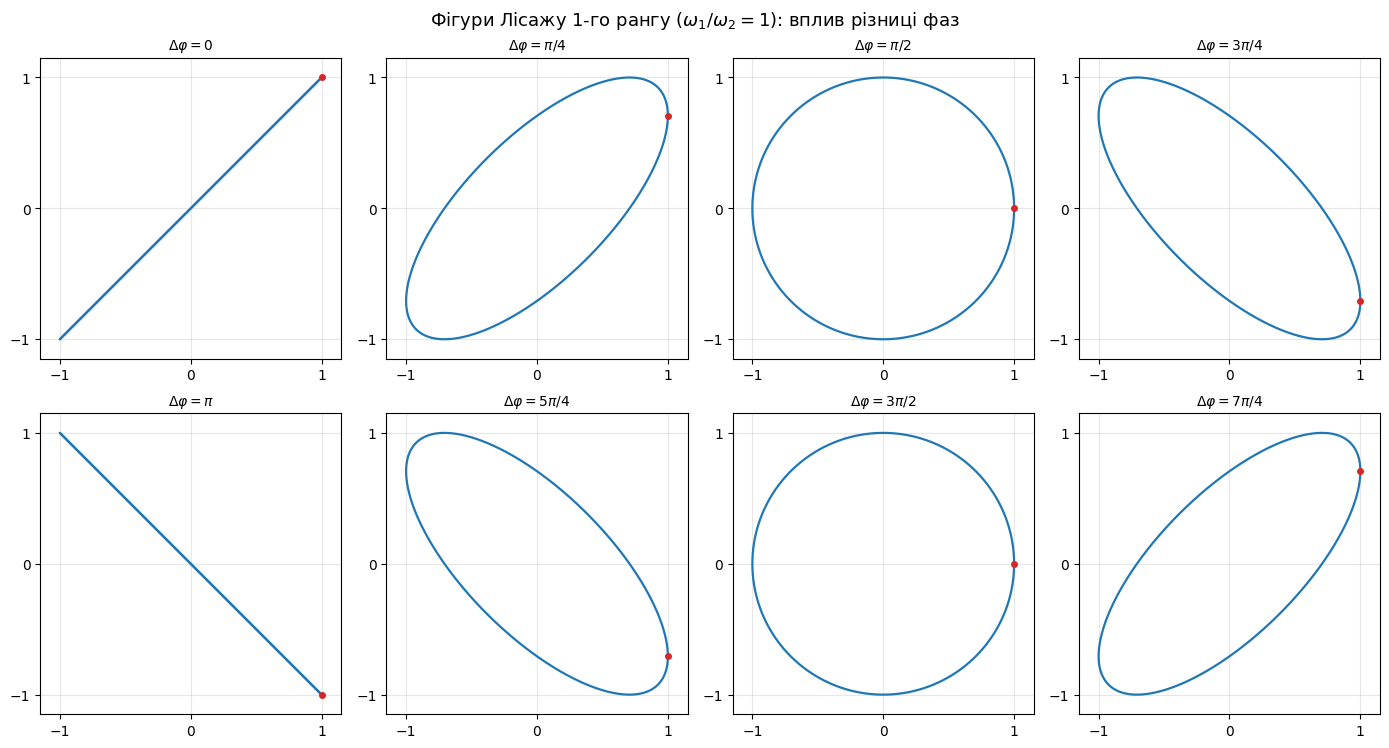

In [ ]:
# Фігури 1-го рангу (ω1/ω2 = 1): як змінюється зображення при зміні різниці фаз Δφ
t = np.linspace(0, 2 * np.pi, 2000)
sweep_figure(lambda dphi: lissajous(1, 1, 0, dphi, t),          # x = cos t, y = cos(t + Δφ)
             r"Фігури Лісажу 1-го рангу ($\omega_1/\omega_2=1$): вплив різниці фаз",
             "fig1_lissajous_rank1.png")

### Характеристика змін: таблиця й чисельна перевірка формул півосей

In [ ]:
# Характеристика фігур 1-го рангу: теорія (півосі, вигляд) проти чисельного розрахунку по кривій
def classify_rank1(dphi):
    """Вигляд фігури та півосі a, b для заданого Δφ."""
    c, s = np.cos(dphi), np.sin(dphi)
    a, b = np.sqrt(1 + abs(c)), np.sqrt(1 - abs(c))
    if abs(s) < 1e-9:
        kind = "відрізок прямої " + ("y = x" if c > 0 else "y = -x")
    elif abs(c) < 1e-9:
        kind = "коло"
    else:
        kind = "еліпс, велика вісь вздовж " + ("y = x" if c > 0 else "y = -x")
    return kind, a, b


print(f"{'Δφ':>6} | {'вигляд фігури':<40} | {'a (теор/числ)':>15} | {'b (теор/числ)':>15} | обхід")
print("-" * 100)
for k in range(8):
    dphi = k * np.pi / 4
    kind, a, b = classify_rank1(dphi)
    x, y = lissajous(1, 1, 0, dphi, t)
    r = np.hypot(x, y)                                        # max r = велика піввісь, min r = мала
    area = 0.5 * np.sum(x[:-1] * np.diff(y) - y[:-1] * np.diff(x))   # орієнтована площа → напрям обходу
    direction = "— (відрізок)" if abs(area) < 1e-6 else ("проти годинникової" if area > 0 else "за годинниковою")
    assert abs(r.max() - a) < 5e-3 and abs(r.min() - b) < 5e-3, "формула півосей не збіглась"
    print(f"{PHASE_TEXT[k]:>6} | {kind:<40} | {a:6.3f} / {r.max():6.3f} | {b:6.3f} / {r.min():6.3f} | {direction}")
print("\nФормули півосей a=√(1+|cosΔφ|), b=√(1−|cosΔφ|) підтверджені чисельно.")

    Δφ | вигляд фігури                            |   a (теор/числ) |   b (теор/числ) | обхід
----------------------------------------------------------------------------------------------------
     0 | відрізок прямої y = x                    |  1.414 /  1.414 |  0.000 /  0.001 | — (відрізок)
   π/4 | еліпс, велика вісь вздовж y = x          |  1.307 /  1.307 |  0.541 /  0.541 | за годинниковою
   π/2 | коло                                     |  1.000 /  1.000 |  1.000 /  1.000 | за годинниковою
  3π/4 | еліпс, велика вісь вздовж y = -x         |  1.307 /  1.307 |  0.541 /  0.541 | за годинниковою
     π | відрізок прямої y = -x                   |  1.414 /  1.414 |  0.000 /  0.001 | — (відрізок)
  5π/4 | еліпс, велика вісь вздовж y = -x         |  1.307 /  1.307 |  0.541 /  0.541 | проти годинникової
  3π/2 | коло                                     |  1.000 /  1.000 |  1.000 /  1.000 | проти годинникової
  7π/4 | еліпс, велика вісь вздовж y = x          |  1.307 /  1.307 |  0.541 

## 2. Фігури 1-го рангу при $\omega_1/\omega_2\approx 1$

Нехай $\omega_1=\omega_2+\delta$, $|\delta|\ll\omega_2$ (беремо $\omega_1/\omega_2=1{,}02$). Тоді
$x=\cos(\omega_2 t+\delta t)$, $y=\cos\omega_2 t$, тобто різниця фаз **повільно зростає з часом**: $\Delta\varphi(t)=\delta\,t$.
За один швидкий період $2\pi/\omega_2$ фігура майже не змінюється й має вигляд фігури 1-го рангу при поточному $\Delta\varphi$,
але з часом вона безперервно «пливе» по всіх цих формах (відрізок → еліпс → коло → еліпс → відрізок …) з періодом биття
$T_б=2\pi/|\delta|$. Малюнок показує «знімки» фігури в моменти $t_k=k\pi/(4\delta)$, коли $\Delta\varphi=k\pi/4$.
Зазор на кривих — наслідок дрейфу фази за один період: крива не замикається.

[збережено] results/fig2_lissajous_near1.png


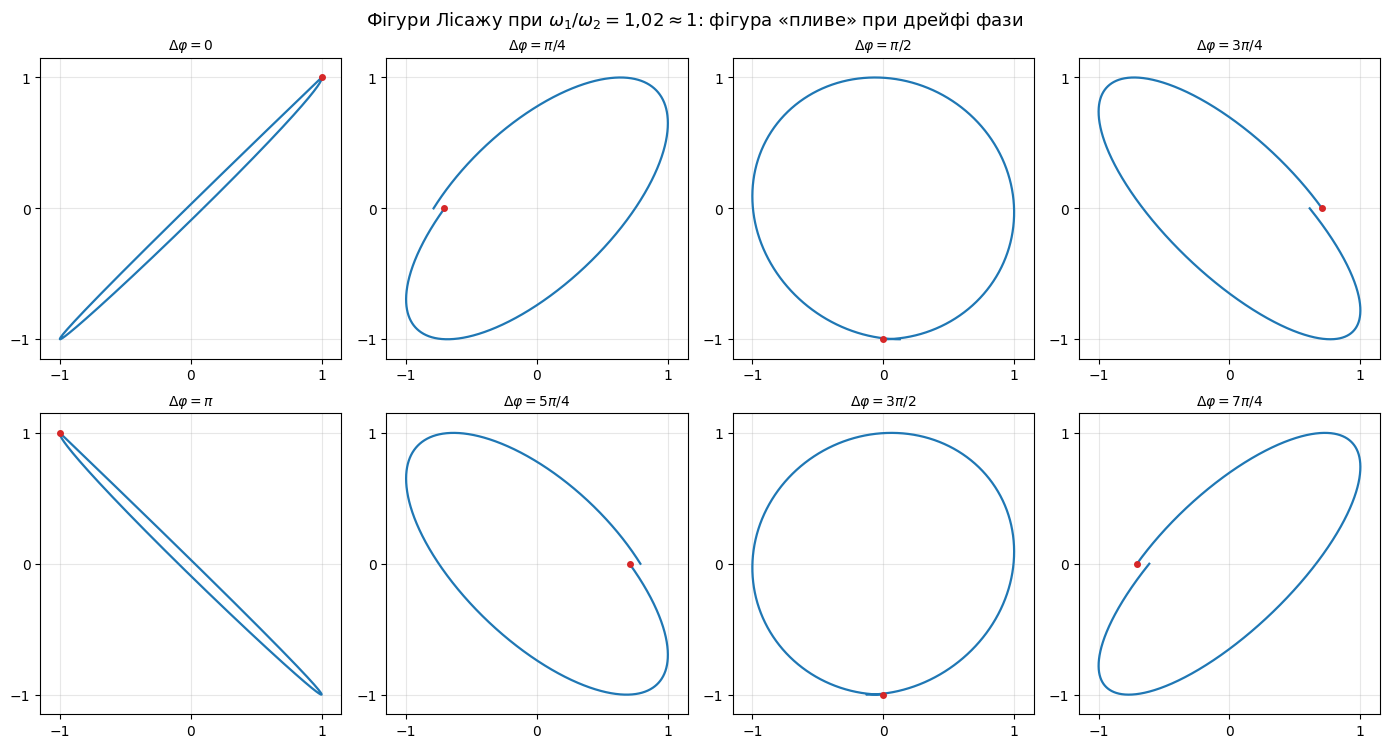

δ = 0.020,  період биття T = 2π/δ = 314.2


In [ ]:
# Вигляд фігури при ω1/ω2 ≈ 1: фаза Δφ(t) = δ·t дрейфує, фігура «пливе»
def near_ratio(w1, w2, rank, title, fname):
    """«Знімки» фігури при ω1/ω2 ≈ rank: за кожним знімком — один швидкий період коливань."""
    delta = w1 - rank * w2                                   # швидкість дрейфу фази
    window = np.linspace(0, 2 * np.pi / w2, 2000)            # один період швидких коливань
    sweep_figure(lambda dphi: lissajous(w1, w2, 0, 0, dphi / delta + window),   # t₀ = Δφ/δ
                 title, fname)
    print(f"δ = {delta:.3f},  період биття T = 2π/δ = {2 * np.pi / delta:.1f}")


near_ratio(1.02, 1.0, 1, r"Фігури Лісажу при $\omega_1/\omega_2=1{,}02\approx1$: фігура «пливе» при дрейфі фази",
           "fig2_lissajous_near1.png")

## 3. Фігури 2-го рангу: $\omega_1/\omega_2 = 2$

$x=\cos(2t+\Delta\varphi)$, $y=\cos t$. Характерні випадки:
* $\Delta\varphi=0$: $x=\cos 2t=2y^2-1$ — **парабола**, відкрита вправо (обходиться туди й назад);
* $\Delta\varphi=\pi$: $x=-(2y^2-1)$ — така сама парабола, відкрита вліво;
* $\Delta\varphi=\pi/2,\ 3\pi/2$: $x^2=4y^2(1-y^2)$ — симетрична **вісімка** з перетином у центрі;
* інші $\Delta\varphi$ — вісімка з двома петлями й точкою самоперетину $(-\cos\Delta\varphi,\,0)$, зміщеною вліво чи вправо;
  при $\Delta\varphi\to0$ або $\pi$ петлі стискаються в параболу.

[збережено] results/fig3_lissajous_rank2.png


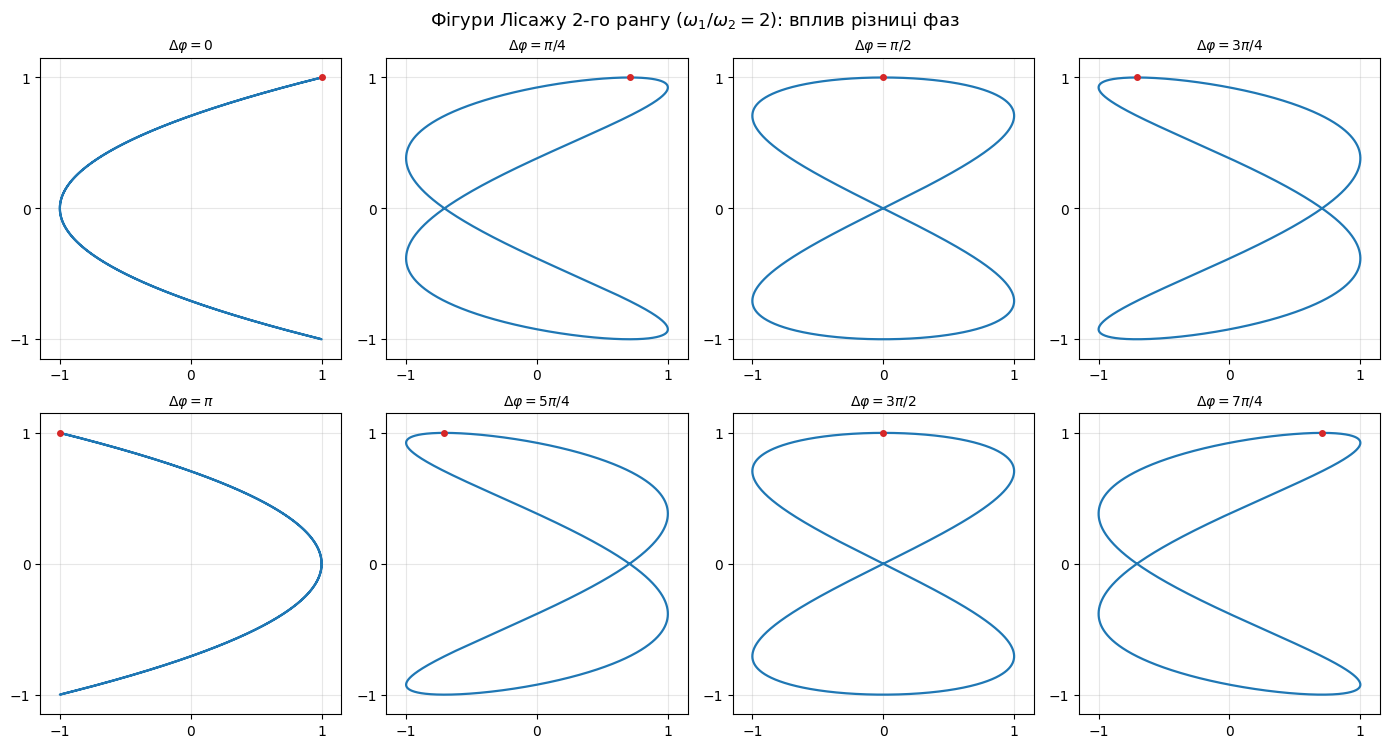

Аналітичні випадки (парабола при Δφ=0, вісімка при Δφ=π/2) підтверджені.


In [ ]:
# Те саме для фігур 2-го рангу (ω1/ω2 = 2)
t = np.linspace(0, 2 * np.pi, 4000)
sweep_figure(lambda dphi: lissajous(2, 1, dphi, 0, t),          # x = cos(2t + Δφ), y = cos t
             r"Фігури Лісажу 2-го рангу ($\omega_1/\omega_2=2$): вплив різниці фаз",
             "fig3_lissajous_rank2.png")

# Перевірка аналітичних випадків
x, y = lissajous(2, 1, 0, 0, t)
assert np.allclose(x, 2 * y**2 - 1), "Δφ=0 має давати параболу x = 2y² − 1"
x, y = lissajous(2, 1, np.pi / 2, 0, t)
assert np.allclose(x**2, 4 * y**2 * (1 - y**2)), "Δφ=π/2 має давати вісімку x² = 4y²(1−y²)"
print("Аналітичні випадки (парабола при Δφ=0, вісімка при Δφ=π/2) підтверджені.")

## 4. Фігури 2-го рангу при $\omega_1/\omega_2\approx 2$

Для $\omega_1=2\omega_2+\delta$ (беремо $\omega_1/\omega_2=2{,}02$) маємо $x=\cos(2\omega_2 t+\delta t)$, $y=\cos\omega_2 t$ —
знову $\Delta\varphi(t)=\delta\,t$ дрейфує повільно, і фігура циклічно проходить форми з п. 3:
парабола (вправо) → вісімка з перетином зліва → симетрична вісімка → вісімка з перетином справа → парабола (вліво) → …

[збережено] results/fig4_lissajous_near2.png


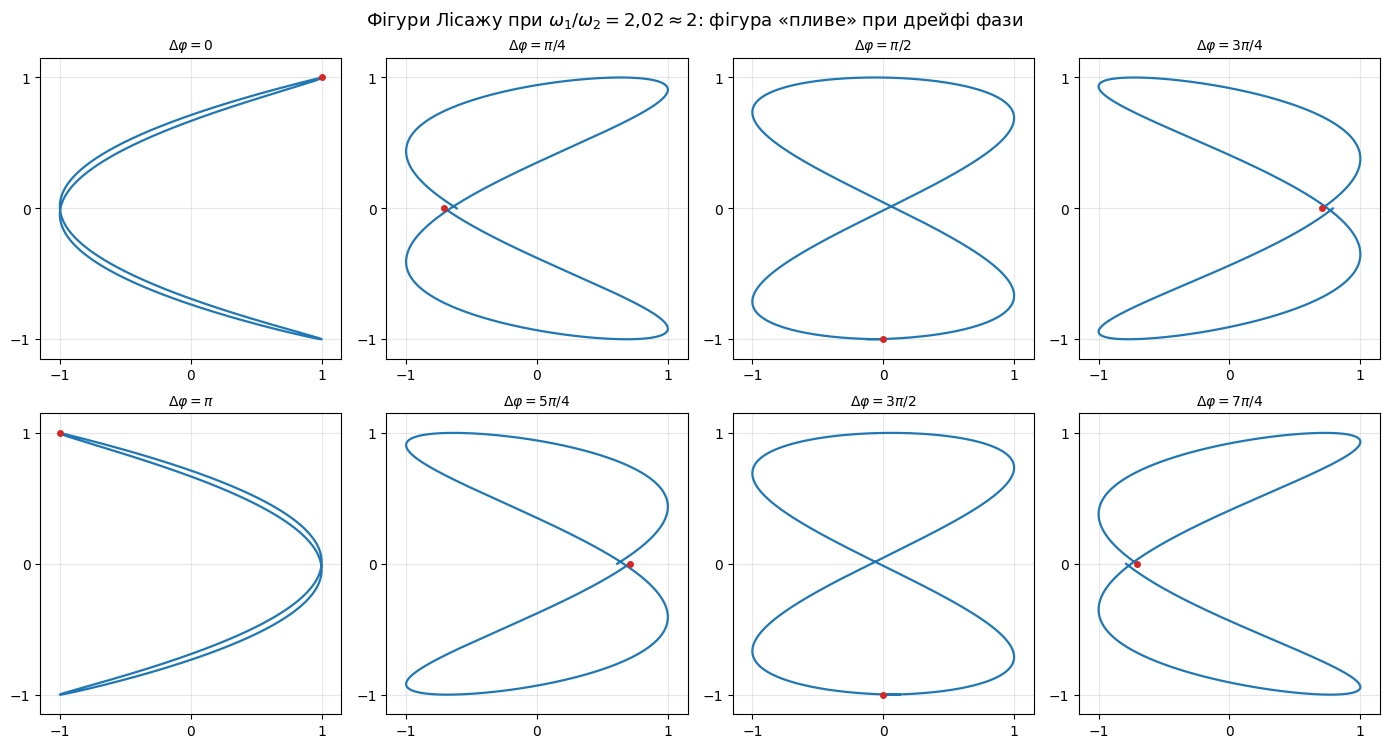

δ = 0.020,  період биття T = 2π/δ = 314.2


In [ ]:
# Вигляд фігури при ω1/ω2 ≈ 2: той самий дрейф фази
near_ratio(2.02, 1.0, 2, r"Фігури Лісажу при $\omega_1/\omega_2=2{,}02\approx2$: фігура «пливе» при дрейфі фази",
           "fig4_lissajous_near2.png")

### Траєкторія за повний період биття

Якщо не обмежувати час одним швидким періодом, а взяти $t\in[0,\,2\pi/|\delta|]$, фігури всіх проміжних фаз накладаються
й заповнюють квадрат «сіткою» еліпсів (для $\approx1$) або вісімок (для $\approx2$), вписаних у квадрат.

[збережено] results/fig5_lissajous_beat.png


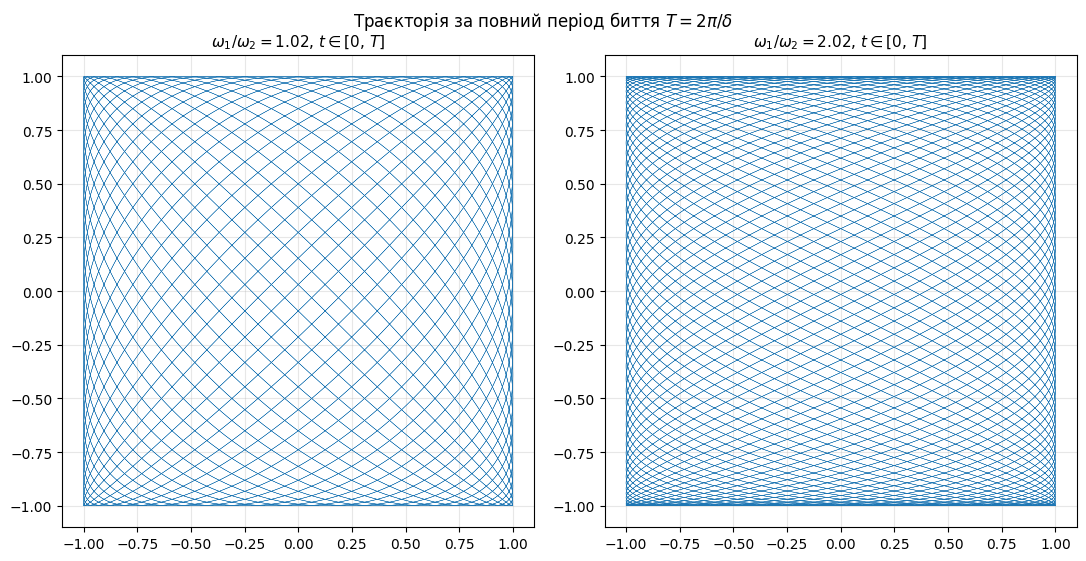

In [ ]:
# Один повний період биття: усі проміжні фігури накладаються
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (w1, w2, rank) in zip(axes, [(1.02, 1.0, 1), (2.02, 1.0, 2)]):
    tb = np.linspace(0, 2 * np.pi / (w1 - rank * w2), 60000)
    x, y = lissajous(w1, w2, 0, 0, tb)
    ax.plot(x, y, lw=0.3)
    ax.set_aspect("equal")
    ax.set_title(rf"$\omega_1/\omega_2={w1}$, $t\in[0,\,T]$", fontsize=11)
fig.suptitle(r"Траєкторія за повний період биття $T=2\pi/\delta$", fontsize=12)
fig.tight_layout()
save(fig, "fig5_lissajous_beat.png")
plt.show()

## 5. Який вигляд мають фігури Лісажу при раціональному та ірраціональному співвідношенні частот?

* $\omega_1/\omega_2=p/q$ **раціональне** → крива **замкнена** й повторюється з періодом $2\pi$ (при $\omega_1=p$, $\omega_2=q$).
  Фігура вписана в квадрат і в загальному випадку торкається кожної вертикальної сторони $p$ разів, кожної горизонтальної — $q$ разів.
  При $\Delta\varphi=0$ крива вироджується у відкриту дугу, яку проходять туди й назад.
* $\omega_1/\omega_2$ **ірраціональне** ($\sqrt2$) → крива **ніколи не замикається** і з часом щільно заповнює весь квадрат $[-1,1]\times[-1,1]$.

[збережено] results/fig6_lissajous_rational.png


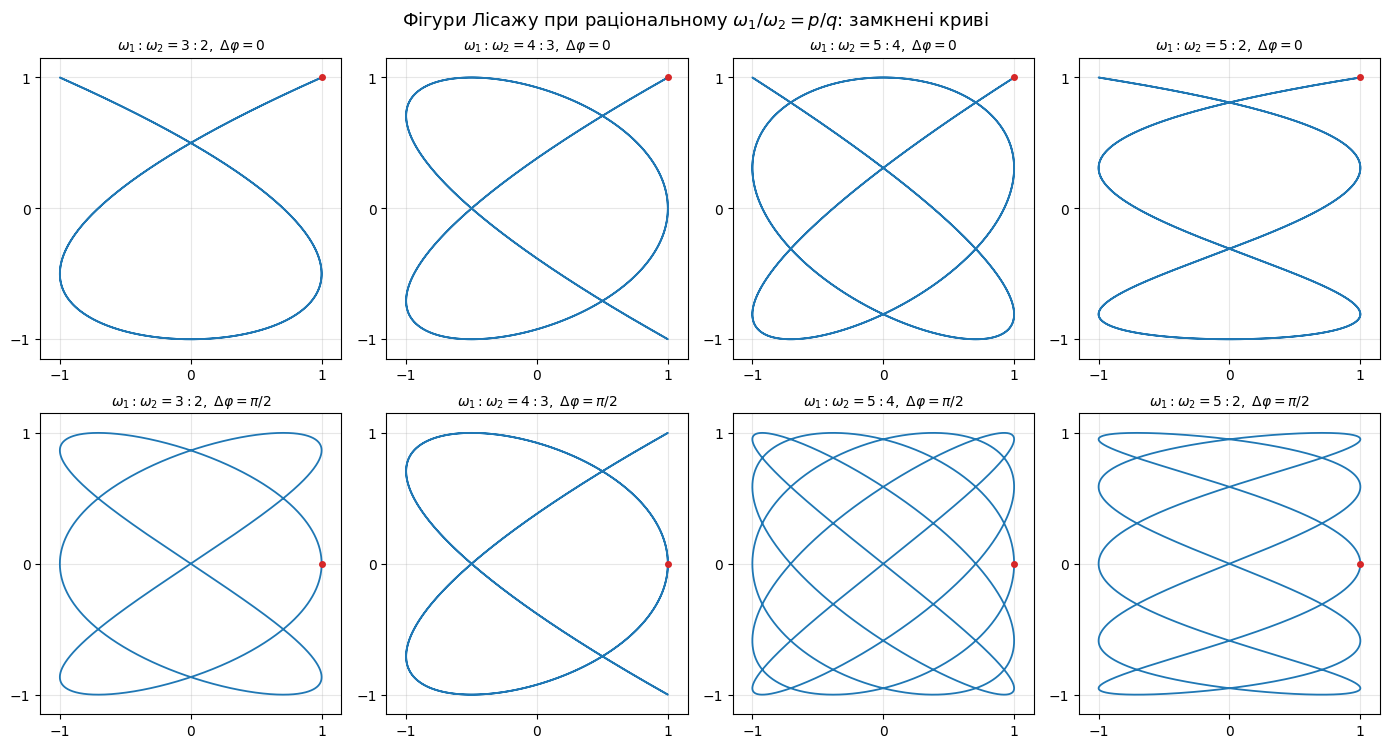

In [ ]:
# Раціональні відношення p:q — замкнені криві
ratios = [(3, 2), (4, 3), (5, 4), (5, 2)]
t = np.linspace(0, 2 * np.pi, 6000)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for col, (p, q) in enumerate(ratios):
    for row, (dphi, lab) in enumerate([(0.0, "0"), (np.pi / 2, r"\pi/2")]):
        x, y = lissajous(p, q, 0, dphi, t)
        draw(axes[row, col], x, y, rf"$\omega_1:\omega_2={p}:{q},\ \Delta\varphi={lab}$", lw=1.3)
fig.suptitle(r"Фігури Лісажу при раціональному $\omega_1/\omega_2=p/q$: замкнені криві", fontsize=13)
fig.tight_layout(h_pad=2)
save(fig, "fig6_lissajous_rational.png")
plt.show()

[збережено] results/fig7_lissajous_irrational.png


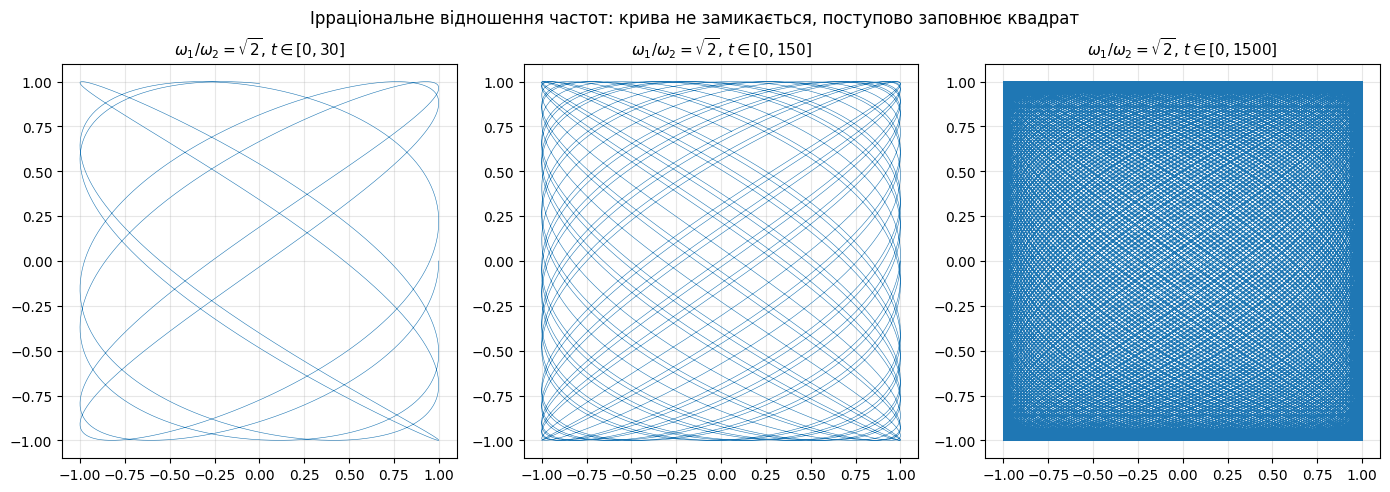

In [ ]:
# Ірраціональне відношення √2 — крива не замикається, заповнює квадрат
w1, w2 = np.sqrt(2), 1.0
horizons = [30, 150, 1500]                   # тривалість моделювання T

fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
for ax, T in zip(axes, horizons):
    tt = np.arange(0, T, 0.01)
    x, y = lissajous(w1, w2, 0, np.pi / 2, tt)
    ax.plot(x, y, lw=0.4)
    ax.set_aspect("equal")
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_title(rf"$\omega_1/\omega_2=\sqrt{{2}}$, $t\in[0,{T}]$", fontsize=11)
fig.suptitle("Ірраціональне відношення частот: крива не замикається, поступово заповнює квадрат", fontsize=12)
fig.tight_layout()
save(fig, "fig7_lissajous_irrational.png")
plt.show()

## 6. Поліном Чебишева $T_n(x)=\cos(n\arccos x)$, $n=5$

$T_5(x)=16x^5-20x^3+5x$. Властивості, видимі на графіку:
* на $[-1,1]$ значення лежать у межах $[-1,1]$; є $n$ нулів $x_k=\cos\frac{(2k-1)\pi}{2n}$;
* є $n+1$ екстремумів $\pm1$ у точках $x=\cos(k\pi/n)$.

Зв'язок із фігурами Лісажу: крива $x=\cos t,\ y=\cos(nt)$ — це **саме графік** $y=T_n(x)$.

Коефіцієнти T_5 (від x⁰): [0, 5, 0, -20, 0, 16]   (тобто 16x⁵ − 20x³ + 5x)
max|T_5(означення) − (явний поліном)| = 2.39e-15
max|T_5(означення) − numpy chebval |  = 2.55e-15
[збережено] results/fig8_chebyshev.png


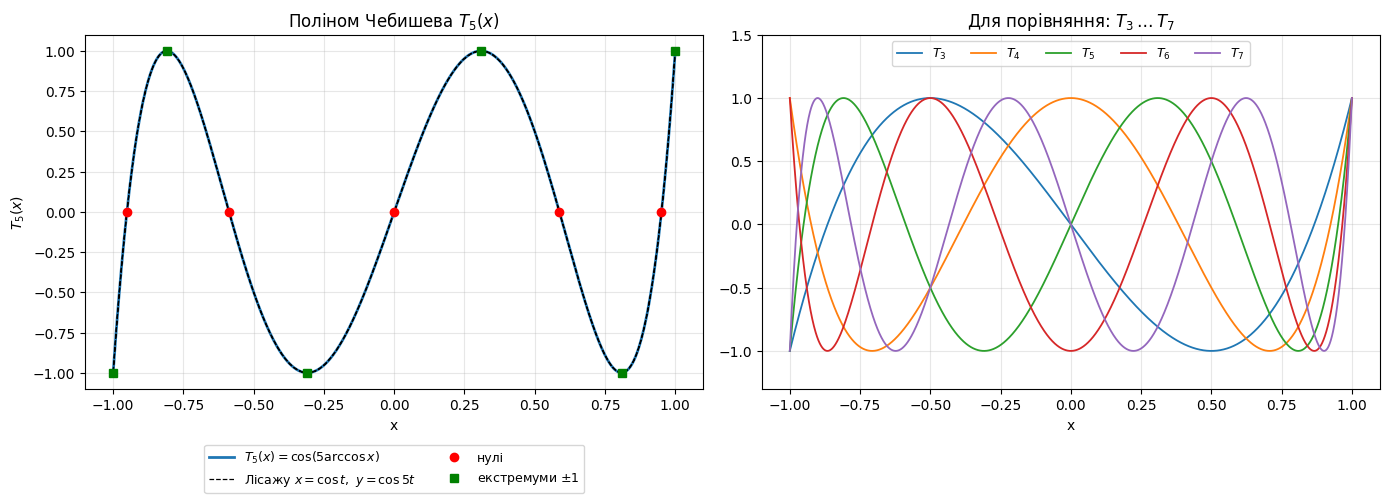

In [ ]:
# Графік полінома Чебишева T_n(x) = cos(n·arccos x), 3 ≤ n ≤ 7
n = 5                                         # порядок за власним вибором, 3 ≤ n ≤ 7
xs = np.linspace(-1, 1, 2001)
Tn = np.cos(n * np.arccos(xs))                # означення T_n(x) = cos(n·arccos x)

# Перевірка: означення = явний поліном = numpy.polynomial.chebyshev
coef = np.polynomial.chebyshev.cheb2poly([0] * n + [1])        # коефіцієнти за степенями x: від x⁰ до xⁿ
explicit = np.polynomial.polynomial.polyval(xs, coef)
from_numpy = np.polynomial.chebyshev.chebval(xs, [0] * n + [1])
print(f"Коефіцієнти T_{n} (від x⁰): {coef.astype(int).tolist()}   (тобто 16x⁵ − 20x³ + 5x)")
print(f"max|T_{n}(означення) − (явний поліном)| = {np.max(np.abs(Tn - explicit)):.2e}")
print(f"max|T_{n}(означення) − numpy chebval |  = {np.max(np.abs(Tn - from_numpy)):.2e}")

zeros = np.cos((2 * np.arange(1, n + 1) - 1) * np.pi / (2 * n))      # нулі
extrema = np.cos(np.arange(0, n + 1) * np.pi / n)                    # точки екстремумів ±1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

ax1.plot(xs, Tn, lw=2, label=rf"$T_{n}(x)=\cos({n}\arccos x)$")
tt = np.linspace(0, 2 * np.pi, 400)
ax1.plot(np.cos(tt), np.cos(n * tt), "k--", lw=0.9, label=rf"Лісажу $x=\cos t,\ y=\cos {n}t$")
ax1.plot(zeros, np.zeros(n), "ro", label="нулі")
ax1.plot(extrema, np.cos(n * np.arccos(extrema)), "gs", ms=6, label=r"екстремуми $\pm1$")
ax1.set_title(rf"Поліном Чебишева $T_{n}(x)$")
ax1.set_xlabel("x")
ax1.set_ylabel(rf"$T_{n}(x)$")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=9)   # легенда під графіком

for m in range(3, 8):                          # для порівняння — усі порядки 3…7
    ax2.plot(xs, np.cos(m * np.arccos(xs)), lw=1.3, label=rf"$T_{m}$")
ax2.set_title(r"Для порівняння: $T_3 \dots T_7$")
ax2.set_xlabel("x")
ax2.legend(ncol=5, fontsize=9, loc="upper center")
ax2.set_ylim(-1.3, 1.5)

fig.tight_layout()
save(fig, "fig8_chebyshev.png")
plt.show()

## Відповіді на питання

**Які зміни відбуваються в зображенні фігури 1-го рангу ($\omega_1/\omega_2=1$) при зміні різниці фаз коливань?**
Вигляд визначається лише $\Delta\varphi$:
* $\Delta\varphi=0$ — відрізок прямої $y=x$;
* $0<\Delta\varphi<\pi/2$ — еліпс, витягнутий вздовж $y=x$;
* $\Delta\varphi=\pi/2$ — коло;
* $\pi/2<\Delta\varphi<\pi$ — еліпс, витягнутий вздовж $y=-x$;
* $\Delta\varphi=\pi$ — відрізок прямої $y=-x$;
* при $\pi<\Delta\varphi<2\pi$ послідовність форм повторюється у зворотному порядку, напрям обходу змінюється на протилежний.

**Якого вигляду набуває фігура при $\omega_1/\omega_2\approx1$?**
Різниця фаз дрейфує: $\Delta\varphi(t)=(\omega_1-\omega_2)t$. Фігура безперервно «пливе» по формах 1-го рангу
(відрізок → еліпс → коло → еліпс → відрізок …) з періодом биття $T=2\pi/|\omega_1-\omega_2|$; за один швидкий період
вона майже замкнена, за період биття — заповнює квадрат сіткою еліпсів.

**Те саме для фігур 2-го рангу ($\omega_1/\omega_2=2$).**
При $\Delta\varphi=0,\pi$ — параболи, відкриті у протилежні боки; при $\Delta\varphi=\pi/2,\ 3\pi/2$ — симетрична вісімка;
при проміжних значеннях — вісімка з точкою самоперетину $(-\cos\Delta\varphi,0)$. При $\omega_1/\omega_2\approx2$ фігура так само
циклічно проходить ці форми (парабола → вісімка → парабола в інший бік → …).

**Який вигляд мають фігури Лісажу при раціональному та ірраціональному співвідношенні частот?**
При раціональному — замкнена крива (повторюється з періодом $T$); при ірраціональному — крива не замикається
й з часом щільно заповнює весь квадрат.

## Висновки (завдання 1)
* Вигляд фігур Лісажу 1-го та 2-го рангу визначається різницею фаз; при $\omega_1/\omega_2\approx1$ та $\approx2$ вона дрейфує,
  тому фігура циклічно змінюється з періодом биття.
* Поліном Чебишева $T_5(x)$ збігається з $16x^5-20x^3+5x$ (похибка $\sim10^{-15}$), має 5 нулів і 6 екстремумів $\pm1$ на $[-1,1]$
  та збігається з кривою Лісажу $x=\cos t,\ y=\cos 5t$.